# RecSys: Домашнее задание 1

Amazon Reviews 2014 - Video Games, 5-core.
Рекомендуем пользователю ещё не оценённые товары. Взаимодействие - отзыв с оценкой.
Релевантным считаем товар с оценкой не ниже 4.


In [2]:
%cd /content/recsys_hometask_1
!git pull

/content/recsys_hometask_1
Already up to date.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import data_utils as data

np.random.seed(42)


## 1. Данные и подготовка

Video Games 5-core содержит около 230 тысяч отзывов. В исходной выборке у каждого пользователя
и товара не менее пяти отзывов. Используем всю выборку.

Поля: `reviewerID` - пользователь, `asin` - товар, `overall` - оценка от 1 до 5,
`unixReviewTime` - время отзыва в секундах Unix. В метаданных используем название,
бренд и категории; связь по `asin`.


In [4]:
reviews_path = data.download(data.REVIEWS_URL, "data/reviews_Video_Games_5.json.gz")
metadata_path = data.download(data.METADATA_URL, "data/meta_Video_Games.json.gz")
raw = data.load_reviews(reviews_path)
raw.head()


,user,item,rating,timestamp
0,A2HD75EMZR8QLN,0700099867,1.0,1341792000
1,A3UR8NLLY1ZHCX,0700099867,4.0,1372550400
2,A1INA0F5CWW3J4,0700099867,1.0,1403913600
3,A1DLMTOTHQ4AST,0700099867,3.0,1315958400
4,A361M14PU2GUEG,0700099867,4.0,1308009600


Проверяем пропуски, дубликаты, активность пользователей, популярность товаров,
разреженность и метаданные. Удаляем записи с некорректными ID, оценками или временем.
Для повторов пользователь-товар оставляем первое наблюдение, чтобы поздняя оценка
не заменила доступную в прошлом. Низкие оценки сохраняем. Товары без метаданных
не удаляем, дополнительных фильтров активности не применяем.


In [5]:
raw.isna().sum()


,0
user,0
item,0
rating,0
timestamp,0


In [6]:
raw[["rating", "timestamp"]].describe()


,rating,timestamp
count,231780.000000,2.317800e+05
mean,4.086397,1.277217e+09
std,1.202330,1.155784e+08
min,1.000000,9.398592e+08
25%,4.000000,1.212970e+09
50%,5.000000,1.317773e+09
75%,5.000000,1.368490e+09
max,5.000000,1.405987e+09


In [7]:
print("Полные дубликаты:", raw.duplicated().sum())
print("Повторы пользователь-товар:", raw.duplicated(["user", "item"]).sum())


Полные дубликаты: 0
Повторы пользователь-товар: 0


In [8]:
interactions, cleaning_report = data.clean_reviews(raw)
display(cleaning_report)

display(pd.DataFrame([
    data.describe_interactions(raw),
    data.describe_interactions(interactions),
], index=["raw", "clean"]))

assert 100_000 <= len(interactions) <= 2_000_000
assert interactions.user.nunique() >= 1_000
assert interactions.item.nunique() >= 1_000


,stage,interactions
0,raw,231780
1,valid fields,231780
2,no exact duplicates,231780
3,first user-item observation,231780


,interactions,users,items,sparsity
raw,231780,24303,10672,0.999106
clean,231780,24303,10672,0.999106


,user_activity,item_popularity
count,24303.000000,10672.000000
mean,9.537094,21.718516
std,12.789697,34.068551
min,5.000000,5.000000
25%,5.000000,7.000000
50%,7.000000,11.000000
75%,10.000000,22.000000
max,773.000000,802.000000


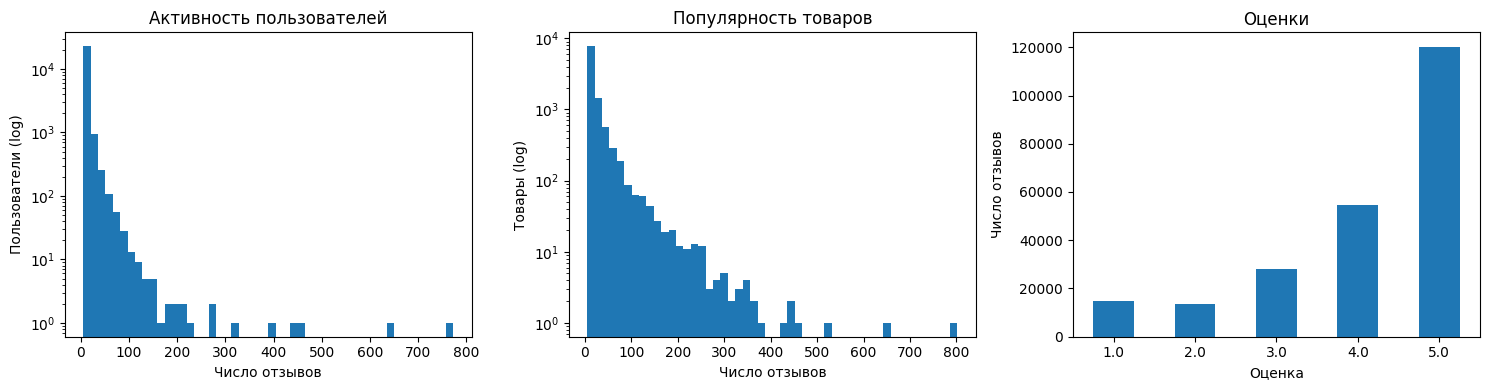

/tmp/ipykernel_15255/435434540.py:16: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  interactions.assign(month=dates.dt.to_period("M").astype(str)).groupby("month").size().plot(


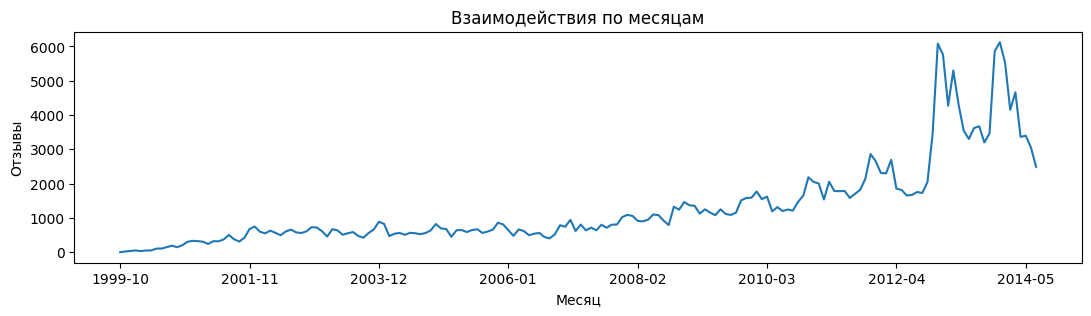

Временной диапазон UTC: 1999-10-14 00:00:00+00:00 - 2014-07-22 00:00:00+00:00


In [9]:
activity = interactions.groupby("user").size()
popularity = interactions.groupby("item").size()
display(pd.DataFrame({"user_activity": activity.describe(),
                      "item_popularity": popularity.describe()}))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(activity, bins=50, log=True)
axes[0].set(title="Активность пользователей", xlabel="Число отзывов", ylabel="Пользователи (log)")
axes[1].hist(popularity, bins=50, log=True)
axes[1].set(title="Популярность товаров", xlabel="Число отзывов", ylabel="Товары (log)")
interactions.rating.value_counts().sort_index().plot.bar(ax=axes[2], rot=0)
axes[2].set(title="Оценки", xlabel="Оценка", ylabel="Число отзывов")
plt.tight_layout()
plt.show()

dates = pd.to_datetime(interactions.timestamp, unit="s", utc=True)
interactions.assign(month=dates.dt.to_period("M").astype(str)).groupby("month").size().plot(
    figsize=(13, 3), title="Взаимодействия по месяцам", ylabel="Отзывы", xlabel="Месяц")
plt.show()
print("Временной диапазон UTC:", dates.min(), "-", dates.max())


,count
items,10672
without_metadata,0
without_title,10392
without_brand,10504
without_categories,0


,item,title,brand,categories
0,0700099867,,,"[[Video Games, PC, Games]]"
1,6050036071,,,"[[Video Games, PlayStation 3, Accessories, Con..."
2,7100027950,,,"[[Video Games, Kids & Family], [Video Games, M..."
3,7293000936,,,"[[Video Games, Wii, Accessories, Cables & Adap..."
4,8176503290,,,"[[Video Games, PC, Games]]"


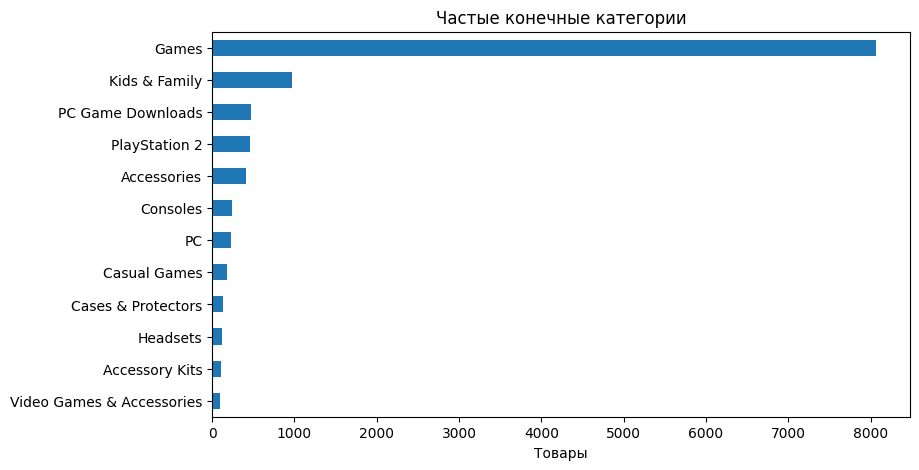

In [10]:
from collections import Counter

metadata = data.load_metadata(metadata_path, interactions.item.unique())
catalog = pd.DataFrame({"item": sorted(interactions.item.unique())}).merge(metadata, on="item", how="left")
metadata_report = pd.Series({
    "items": len(catalog),
    "without_metadata": int((~catalog.item.isin(metadata.item)).sum()),
    "without_title": int(catalog.title.fillna("").eq("").sum()),
    "without_brand": int(catalog.brand.fillna("").eq("").sum()),
    "without_categories": int(catalog.categories.map(lambda x: not isinstance(x, list) or not x).sum()),
})
display(metadata_report.to_frame("count"))
display(catalog.head())
category_counts = Counter()
for paths in metadata.categories:

    leaves = {path[-1] for path in paths if isinstance(path, list) and path}
    category_counts.update(leaves)
if category_counts:
    pd.Series(dict(category_counts.most_common(12))).sort_values().plot.barh(
        figsize=(9, 5), title="Частые конечные категории", xlabel="Товары")
    plt.show()


## 2. Оценка качества

Разбиваем по времени: примерно 80% взаимодействий - train, 10% - validation,
10% - test. Общие временные границы исключают обучение на будущих событиях;
одинаковые timestamp остаются в одной части.

Кандидаты - все товары train. Новых пользователей и товары исключаем из оценки,
их количество выводим отдельно. Оцениваем пользователей хотя бы с одним релевантным
товаром в соответствующей части. Уже оценённые товары исключаем независимо от оценки.
Для validation известная история - train, для test - train и validation.
Модель и каталог фиксируем по train, перед test не переобучаем.
Этот протокол используем для всех моделей.

Основная метрика - **NDCG@10**: учитывает позиции релевантных товаров.
Дополнительная - **Recall@10**: доля найденных релевантных товаров.
Усредняем по пользователям.


In [11]:
K = 10
RELEVANCE_THRESHOLD = 4
TRAIN_FRACTION = 0.8
VALIDATION_FRACTION = 0.1
BATCH_SIZE = 128

train, validation, test, boundaries = data.temporal_split(
    interactions, TRAIN_FRACTION, VALIDATION_FRACTION)
assert train.timestamp.max() < validation.timestamp.min()
assert validation.timestamp.max() < test.timestamp.min()
assert len(train) + len(validation) + len(test) == len(interactions)
display(pd.DataFrame([
    {"split": name, **data.describe_interactions(frame),
     "start_utc": pd.to_datetime(frame.timestamp.min(), unit="s", utc=True),
     "end_utc": pd.to_datetime(frame.timestamp.max(), unit="s", utc=True)}
    for name, frame in [("train", train), ("validation", validation), ("test", test)]
]))

users, items = data.make_mappings(train)
X_positive = data.interaction_matrix(train, users, items, RELEVANCE_THRESHOLD)
X_seen = data.interaction_matrix(train, users, items)
validation_targets, validation_coverage = data.evaluation_targets(
    validation, users, items, X_seen, RELEVANCE_THRESHOLD)
display(pd.Series(validation_coverage).to_frame("validation"))
assert validation_targets, "Нет пользователей для оценки: проверьте разбиение"
print("Матрица train:", X_positive.shape, "; положительных пар:", X_positive.nnz)
print("Пользователей без положительной истории train:", int((X_positive.getnnz(axis=1) == 0).sum()))


,split,interactions,users,items,sparsity,start_utc,end_utc
0,train,185349,22209,10093,0.999173,1999-10-14 00:00:00+00:00,2013-08-21 00:00:00+00:00
1,validation,23133,7654,5191,0.999418,2013-08-22 00:00:00+00:00,2014-01-17 00:00:00+00:00
2,test,23298,6985,5477,0.999391,2014-01-18 00:00:00+00:00,2014-07-22 00:00:00+00:00


,validation
holdout_rows,23133
cold_user_rows,6594
cold_item_rows,7425
warm_rows,10568
excluded_seen_positive_rows,0
evaluated_users,3986
relevant_pairs,8429


Матрица train: (22209, 10093) ; положительных пар: 138586
Пользователей без положительной истории train: 550


## 3. Item-based CF

Положительная история: $X_{ui}=1$, если в train есть оценка $r_{ui}\ge4$, иначе 0.
$n_{ij}=(X^TX)_{ij}$ - число общих пользователей товаров,
$n_i=\sum_u X_{ui}$. Используем косинусное сходство со сглаживанием:

$$
s_{ij}=\frac{n_{ij}}{\sqrt{n_i n_j}}\frac{n_{ij}}{n_{ij}+\lambda},\qquad s_{ii}=0.
$$

Без общих пользователей сходство равно нулю; при $\lambda=0$ сглаживания нет.
Сглаживание уменьшает влияние случайных совпадений. Для каждого товара сохраняем
$L$ соседей с наибольшим сходством в матрице $W$.
Баллы рекомендаций:

$$
\hat y_{uj}=(XW)_{uj}=\sum_{i:X_{ui}=1}W_{ij}.
$$

Выбираем 10 неизвестных товаров с максимальным баллом. При равенстве баллов
приоритет у более популярных в положительном train товаров, затем у меньшего ID.
Для пользователей без положительной истории получается рекомендация по популярности.


### Подбор параметров

`n_neighbors ∈ {50, 100, 200}`, `shrinkage ∈ {0, 10}`.
Выбираем максимум NDCG@10 на validation; при равенстве - меньше соседей,
затем меньше `shrinkage`. Размер блока - 256, пакет оценки - 128 пользователей.


In [12]:
import json
from pathlib import Path
from itertools import product

from models.item_knn import ItemKNN
from evaluation import evaluate

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

search_space = {"n_neighbors": [50, 100, 200], "shrinkage": [0.0, 10.0]}
validation_rows = []
for neighbors, shrinkage in product(search_space["n_neighbors"], search_space["shrinkage"]):
    candidate = ItemKNN(n_neighbors=neighbors, shrinkage=shrinkage, block_size=256)
    candidate.fit(X_positive)
    scores = evaluate(candidate, validation_targets, X_seen, k=K, batch_size=BATCH_SIZE)
    row = {"model": "ItemKNN", "n_neighbors": neighbors, "shrinkage": shrinkage,
           **scores}
    validation_rows.append(row)
    pd.DataFrame(validation_rows).to_csv(RESULTS_DIR / "item_knn_validation.csv", index=False)
    print(row)
    del candidate

validation_results = pd.DataFrame(validation_rows).sort_values(
    ["NDCG@10", "n_neighbors", "shrinkage"], ascending=[False, True, True], kind="stable")
display(validation_results)
best_row = validation_results.iloc[0]
best_params = {"n_neighbors": int(best_row.n_neighbors), "shrinkage": float(best_row.shrinkage)}
(RESULTS_DIR / "item_knn_best_params.json").write_text(
    json.dumps(best_params, indent=2), encoding="utf-8")
print("Выбрано по validation NDCG@10:", best_params)
best_model = ItemKNN(**best_params).fit(X_positive)


{'model': 'ItemKNN', 'n_neighbors': 50, 'shrinkage': 0.0, 'NDCG@10': 0.017278445861105905, 'Recall@10': 0.026190122747151292, 'users': 3986}
{'model': 'ItemKNN', 'n_neighbors': 50, 'shrinkage': 10.0, 'NDCG@10': 0.030598437561890846, 'Recall@10': 0.044732039865995554, 'users': 3986}
{'model': 'ItemKNN', 'n_neighbors': 100, 'shrinkage': 0.0, 'NDCG@10': 0.018324191512042974, 'Recall@10': 0.026990108369343582, 'users': 3986}
{'model': 'ItemKNN', 'n_neighbors': 100, 'shrinkage': 10.0, 'NDCG@10': 0.030275034993554703, 'Recall@10': 0.044335672791071645, 'users': 3986}
{'model': 'ItemKNN', 'n_neighbors': 200, 'shrinkage': 0.0, 'NDCG@10': 0.019129750378249207, 'Recall@10': 0.028750436183359308, 'users': 3986}
{'model': 'ItemKNN', 'n_neighbors': 200, 'shrinkage': 10.0, 'NDCG@10': 0.03034875388040506, 'Recall@10': 0.044091640573735796, 'users': 3986}


,model,n_neighbors,shrinkage,NDCG@10,Recall@10,users
1,ItemKNN,50,10.0,0.030598,0.044732,3986
5,ItemKNN,200,10.0,0.030349,0.044092,3986
3,ItemKNN,100,10.0,0.030275,0.044336,3986
4,ItemKNN,200,0.0,0.019130,0.028750,3986
2,ItemKNN,100,0.0,0.018324,0.026990,3986
0,ItemKNN,50,0.0,0.017278,0.026190,3986


Выбрано по validation NDCG@10: {'n_neighbors': 50, 'shrinkage': 10.0}


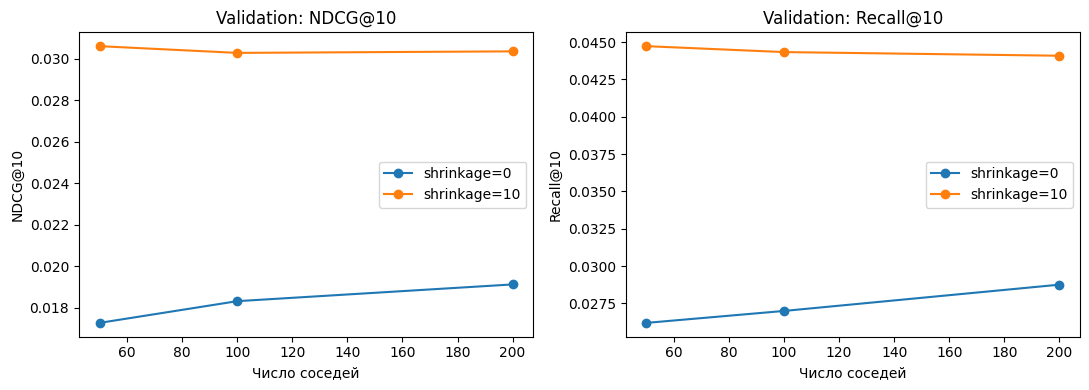

Лучший validation NDCG@10: 0.03060; Recall@10: 0.04473
Разница лучших NDCG@10 со сглаживанием и без: +0.01147


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for shrinkage, group in validation_results.groupby("shrinkage"):
    group = group.sort_values("n_neighbors")
    for ax, metric in zip(axes, ["NDCG@10", "Recall@10"]):
        ax.plot(group.n_neighbors, group[metric], marker="o", label=f"shrinkage={shrinkage:g}")
        ax.set(xlabel="Число соседей", ylabel=metric, title=f"Validation: {metric}")
        ax.legend()
plt.tight_layout()
plt.show()

unsmoothed = validation_results[validation_results.shrinkage.eq(0)].iloc[0]
smoothed = validation_results[validation_results.shrinkage.eq(10)].iloc[0]
print(f"Лучший validation NDCG@10: {best_row['NDCG@10']:.5f}; "
      f"Recall@10: {best_row['Recall@10']:.5f}")
print(f"Разница лучших NDCG@10 со сглаживанием и без: "
      f"{smoothed['NDCG@10'] - unsmoothed['NDCG@10']:+.5f}")


## 4. iALS

Используем неявную обратную связь: $p_{ui}=X_{ui}$, где $X$ - та же положительная
матрица train. Уверенность $c_{ui}=1+\alpha p_{ui}$.
Неизвестные пары имеют целевой сигнал 0 и уверенность 1.
Минимизируем взвешенную ошибку с регуляризацией:

$$
\min_{U,V}\sum_{u,i}c_{ui}(p_{ui}-U_u^TV_i)^2
+\lambda(\|U\|_F^2+\|V\|_F^2).
$$

Поочерёдно фиксируем факторы товаров и пользователей. Для пользователя решаем:

$$
U_u=(V^TC_uV+\lambda I)^{-1}V^TC_up_u,
$$

где $C_u$ - диагональная матрица уверенностей. Факторы товаров обновляем аналогично.
Баллы рекомендаций: $\hat y_{ui}=U_u^TV_i$.

### Подбор параметров

`factors ∈ {32, 64}`, `alpha ∈ {10, 40}`.
Регуляризация 0.1, число итераций 10, seed 42.
Выбираем максимум NDCG@10 на validation; при равенстве сохраняем первый вариант.

In [14]:
from models.ials import IALS

ials_rows = []
best_ials_model = None
best_ials_score = -np.inf

for factors, alpha in product([32, 64], [10.0, 40.0]):
    candidate = IALS(factors=factors, alpha=alpha, regularization=0.1,
                     iterations=10, seed=42).fit(X_positive)
    scores = evaluate(candidate, validation_targets, X_seen, k=K, batch_size=BATCH_SIZE)
    row = {"model": "iALS", "factors": factors, "alpha": alpha,
           "regularization": 0.1, "iterations": 10, "seed": 42, **scores}
    ials_rows.append(row)
    pd.DataFrame(ials_rows).to_csv(RESULTS_DIR / "ials_validation.csv", index=False)
    print(row)
    if scores["NDCG@10"] > best_ials_score:
        best_ials_score = scores["NDCG@10"]
        best_ials_model = candidate
    del candidate

ials_results = pd.DataFrame(ials_rows).sort_values("NDCG@10", ascending=False, kind="stable")
display(ials_results)
ials_best = ials_results.iloc[0]
ials_best_params = {"factors": int(ials_best.factors), "alpha": float(ials_best.alpha),
                    "regularization": 0.1, "iterations": 10, "seed": 42}
(RESULTS_DIR / "ials_best_params.json").write_text(json.dumps(ials_best_params, indent=2))
print("Выбрано по validation NDCG@10:", ials_best_params)

{'model': 'iALS', 'factors': 32, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 10, 'seed': 42, 'NDCG@10': 0.03310064527784548, 'Recall@10': 0.05132084464593448, 'users': 3986}
{'model': 'iALS', 'factors': 32, 'alpha': 40.0, 'regularization': 0.1, 'iterations': 10, 'seed': 42, 'NDCG@10': 0.032936541729941086, 'Recall@10': 0.05135960907960507, 'users': 3986}
{'model': 'iALS', 'factors': 64, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 10, 'seed': 42, 'NDCG@10': 0.03456915085124072, 'Recall@10': 0.053470700655914694, 'users': 3986}
{'model': 'iALS', 'factors': 64, 'alpha': 40.0, 'regularization': 0.1, 'iterations': 10, 'seed': 42, 'NDCG@10': 0.034106170467875445, 'Recall@10': 0.05335950700483143, 'users': 3986}


,model,factors,alpha,regularization,iterations,seed,NDCG@10,Recall@10,users
2,iALS,64,10.0,0.1,10,42,0.034569,0.053471,3986
3,iALS,64,40.0,0.1,10,42,0.034106,0.053360,3986
0,iALS,32,10.0,0.1,10,42,0.033101,0.051321,3986
1,iALS,32,40.0,0.1,10,42,0.032937,0.051360,3986


Выбрано по validation NDCG@10: {'factors': 64, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 10, 'seed': 42}


## 5. EASE

Обучаем линейную модель на той же положительной матрице $X$:

$$
\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,
\qquad B_{ii}=0.
$$

Нулевая диагональ не позволяет копировать взаимодействие товара с самим собой.
Решение:

$$
P=(X^TX+\lambda I)^{-1},\qquad
B_{ij}=-\frac{P_{ij}}{P_{jj}}\ (i\ne j),\qquad B_{ii}=0.
$$

Баллы рекомендаций: $\hat Y=XB$.
Как и в ItemKNN, равные баллы разрешаем по популярности в положительном train,
затем по ID.

### Подбор параметров

`regularization ∈ {100, 500, 1000}`.
Выбираем максимум NDCG@10 на validation; при равенстве - меньшую регуляризацию.

In [15]:
from models.ease import EASE

ease_rows = []
best_ease_model = None
best_ease_score = -np.inf

for regularization in [100.0, 500.0, 1000.0]:
    candidate = EASE(regularization=regularization).fit(X_positive)
    scores = evaluate(candidate, validation_targets, X_seen, k=K, batch_size=BATCH_SIZE)
    row = {"model": "EASE", "regularization": regularization, **scores}
    ease_rows.append(row)
    pd.DataFrame(ease_rows).to_csv(RESULTS_DIR / "ease_validation.csv", index=False)
    print(row)
    if scores["NDCG@10"] > best_ease_score:
        best_ease_score = scores["NDCG@10"]
        best_ease_model = candidate
    del candidate

ease_results = pd.DataFrame(ease_rows).sort_values("NDCG@10", ascending=False, kind="stable")
display(ease_results)
ease_best_params = {"regularization": float(ease_results.iloc[0].regularization)}
(RESULTS_DIR / "ease_best_params.json").write_text(json.dumps(ease_best_params, indent=2))
print("Выбрано по validation NDCG@10:", ease_best_params)

{'model': 'EASE', 'regularization': 100.0, 'NDCG@10': 0.03677285278221114, 'Recall@10': 0.05445647571827592, 'users': 3986}
{'model': 'EASE', 'regularization': 500.0, 'NDCG@10': 0.036145042681887625, 'Recall@10': 0.05336598501303063, 'users': 3986}
{'model': 'EASE', 'regularization': 1000.0, 'NDCG@10': 0.035193168585592564, 'Recall@10': 0.05145980037980134, 'users': 3986}


,model,regularization,NDCG@10,Recall@10,users
0,EASE,100.0,0.036773,0.054456,3986
1,EASE,500.0,0.036145,0.053366,3986
2,EASE,1000.0,0.035193,0.051460,3986


Выбрано по validation NDCG@10: {'regularization': 100.0}


## 6. FM

Признаки: ID пользователя, ID товара и категории товара, включая платформу.
Категории позволяют учитывать общие предпочтения к платформам и типам товаров.
Словарь признаков строим только по каталогу train. ID имеют значение 1,
каждая из $m$ категорий товара - $1/\sqrt{m}$.
Пропущенную категорию заменяем на `unknown`.

Предполагаем, что категории из снимка метаданных были доступны и неизменны
в момент рекомендации. Истории их изменений нет, это ограничение эксперимента.

Факторизационная машина учитывает попарные взаимодействия признаков:

$$
\hat y(x)=w_0+\sum_j w_jx_j+
\frac12\sum_f\left[\left(\sum_j v_{jf}x_j\right)^2-\sum_j v_{jf}^2x_j^2\right].
$$

Обучаем с бинарной кросс-энтропией и L2-регуляризацией.

В отзывах train оценки 4-5 имеют метку 1, оценки 1-3 - метку 0.
Каждую эпоху на положительный отзыв добавляем два случайных неизвестных товара
с меткой 0. Исключаем все известные в train товары; validation и test при выборе
негативов не используем. При оценке используем общий каталог кандидатов.

### Подбор параметров

`factors ∈ {16, 32}`, `learning_rate ∈ {0.001, 0.003}`.
L2-регуляризация $10^{-5}$, 10 эпох, пакет 2048, seed 42.
Оптимизатор Adam. Выбираем максимум NDCG@10 на validation;
при равенстве сохраняем первый вариант.

In [ ]:
import torch
from models.fm import FM

fm_device = "cuda" if torch.cuda.is_available() else "cpu"
fm_rows = []
best_fm_model = None
best_fm_score = -np.inf

for factors, learning_rate in product([16, 32], [0.001, 0.003]):
    candidate = FM(factors=factors, learning_rate=learning_rate,
                   regularization=1e-5, epochs=10, batch_size=2048,
                   negatives=2, seed=42, device=fm_device)
    candidate.fit(train, users, items, metadata, X_seen, RELEVANCE_THRESHOLD)
    scores = evaluate(candidate, validation_targets, X_seen, k=K, batch_size=BATCH_SIZE)
    row = {"model": "FM", "factors": factors, "learning_rate": learning_rate,
           "regularization": 1e-5, "epochs": 10, "batch_size": 2048,
           "negatives": 2, "seed": 42, **scores}
    fm_rows.append(row)
    pd.DataFrame(fm_rows).to_csv(RESULTS_DIR / "fm_validation.csv", index=False)
    print(row)
    if scores["NDCG@10"] > best_fm_score:
        best_fm_score = scores["NDCG@10"]
        best_fm_model = candidate
    del candidate

fm_results = pd.DataFrame(fm_rows).sort_values("NDCG@10", ascending=False, kind="stable")
display(fm_results)
fm_best = fm_results.iloc[0]
fm_best_params = {"factors": int(fm_best.factors),
                  "learning_rate": float(fm_best.learning_rate),
                  "regularization": 1e-5, "epochs": 10,
                  "batch_size": 2048, "negatives": 2, "seed": 42}
(RESULTS_DIR / "fm_best_params.json").write_text(json.dumps(fm_best_params, indent=2))
print("Выбрано по validation NDCG@10:", fm_best_params)

### Влияние метаданных

Сравниваем FM с категориями и без них при одинаковых настройках и seed.

In [ ]:
fm_without_metadata = FM(**fm_best_params, use_metadata=False, device=fm_device)
fm_without_metadata.fit(train, users, items, metadata, X_seen, RELEVANCE_THRESHOLD)
fm_ids_scores = evaluate(fm_without_metadata, validation_targets, X_seen,
                         k=K, batch_size=BATCH_SIZE)
fm_feature_comparison = pd.DataFrame([
    {"features": "ID + категории", "NDCG@10": float(fm_best["NDCG@10"]),
     "Recall@10": float(fm_best["Recall@10"])},
    {"features": "Только ID", "NDCG@10": fm_ids_scores["NDCG@10"],
     "Recall@10": fm_ids_scores["Recall@10"]},
])
display(fm_feature_comparison)
fm_feature_comparison.to_csv(RESULTS_DIR / "fm_features_validation.csv", index=False)

## 7. iALS с кастомным таргетом

Кастомный таргет учитывает величину оценки и давность взаимодействия:

$$
q_{ui}=\begin{cases}
\dfrac{r_{ui}-3}{2}\,2^{-\Delta t_{ui}/h}, & (u,i)\in train,\ r_{ui}\ge4,\\
0, & \text{иначе},
\end{cases}
\qquad \Delta t_{ui}=\dfrac{t_0-t_{ui}}{86400}.
$$

$t_0$ - временная граница train, $h$ - период полураспада в днях.
Оценка 5 даёт больший сигнал, чем 4; давние взаимодействия влияют слабее.

Confidence оставляем прежним: $c_{ui}=1+\alpha X_{ui}$, где $X$ - бинарная
положительная история. Функция потерь:

$$
\min_{U,V}\sum_{u,i}c_{ui}(q_{ui}-U_u^TV_i)^2+
\lambda(\|U\|_F^2+\|V\|_F^2).
$$

Обновления ALS остаются теми же, но правая часть использует $q_u$ вместо $p_u$.
Баллы рекомендаций: $\hat y_{ui}=U_u^TV_i$.
Таргет строим только по train; релевантность на validation и test не меняется.

### Подбор и сравнение

`half_life ∈ {180, 730}` дней. Факторы, alpha, регуляризацию, число итераций
и seed берём из выбранного базового iALS. Выбираем максимум NDCG@10 на validation;
при равенстве - меньший `half_life`.

In [ ]:
from models.custom_ials import CustomIALS

custom_rows = []
best_custom_ials_model = None
best_custom_ials_score = -np.inf

for half_life in [180, 730]:
    custom_targets = data.rating_time_targets(
        train, users, items, boundaries[0], half_life, RELEVANCE_THRESHOLD)
    candidate = CustomIALS(**ials_best_params).fit(custom_targets)
    scores = evaluate(candidate, validation_targets, X_seen, k=K, batch_size=BATCH_SIZE)
    row = {"model": "Custom iALS", **ials_best_params,
           "half_life": half_life, **scores}
    custom_rows.append(row)
    pd.DataFrame(custom_rows).to_csv(RESULTS_DIR / "custom_ials_validation.csv", index=False)
    print(row)
    if scores["NDCG@10"] > best_custom_ials_score:
        best_custom_ials_score = scores["NDCG@10"]
        best_custom_ials_model = candidate
    del candidate

custom_ials_results = pd.DataFrame(custom_rows).sort_values(
    "NDCG@10", ascending=False, kind="stable")
display(custom_ials_results)
custom_ials_best = custom_ials_results.iloc[0]
custom_ials_best_params = {**ials_best_params, "half_life": int(custom_ials_best.half_life)}
(RESULTS_DIR / "custom_ials_best_params.json").write_text(
    json.dumps(custom_ials_best_params, indent=2))
print("Выбрано по validation NDCG@10:", custom_ials_best_params)

target_comparison = pd.DataFrame([
    {"model": "iALS", "NDCG@10": float(ials_best["NDCG@10"]),
     "Recall@10": float(ials_best["Recall@10"])},
    {"model": "Custom iALS", "NDCG@10": float(custom_ials_best["NDCG@10"]),
     "Recall@10": float(custom_ials_best["Recall@10"])},
])
display(target_comparison)
target_comparison.to_csv(RESULTS_DIR / "ials_targets_validation.csv", index=False)